## CL-1 Lab Assignment 1 (Group A): Feature Transformation
### PCA for Dimensionality Reduction on Wine dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

plt.rcParams["figure.figsize"] = (10, 6)

In [3]:
FILE = "Wine.csv"
df = pd.read_csv(FILE)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (178, 14)


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [3]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(df.isna().sum().to_frame("missing"))

print("\nSummary statistics:")
display(df.describe().T)

print("\nTarget distribution:")
display(df["Customer_Segment"].value_counts().sort_index().to_frame("count"))

Columns:
['Alcohol', 'Malic_Acid', 'Ash', 'Ash_Alcanity', 'Magnesium', 'Total_Phenols', 'Flavanoids', 'Nonflavanoid_Phenols', 'Proanthocyanins', 'Color_Intensity', 'Hue', 'OD280', 'Proline', 'Customer_Segment']

Data types:


,dtype
Alcohol,float64
Malic_Acid,float64
Ash,float64
Ash_Alcanity,float64
Magnesium,int64
Total_Phenols,float64
Flavanoids,float64
Nonflavanoid_Phenols,float64
Proanthocyanins,float64
Color_Intensity,float64



Missing values:


,missing
Alcohol,0
Malic_Acid,0
Ash,0
Ash_Alcanity,0
Magnesium,0
Total_Phenols,0
Flavanoids,0
Nonflavanoid_Phenols,0
Proanthocyanins,0
Color_Intensity,0



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
Malic_Acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
Ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
Ash_Alcanity,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
Magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
Total_Phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
Flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
Nonflavanoid_Phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
Proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
Color_Intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00



Target distribution:


,count
Customer_Segment,
1,59
2,71
3,48


In [4]:
target_col = "Customer_Segment"

X = df.drop(columns=[target_col])
y = df[target_col]

print("Number of original features:", X.shape[1])
print("Feature names:")
print(X.columns.tolist())

Number of original features: 13
Feature names:
['Alcohol', 'Malic_Acid', 'Ash', 'Ash_Alcanity', 'Magnesium', 'Total_Phenols', 'Flavanoids', 'Nonflavanoid_Phenols', 'Proanthocyanins', 'Color_Intensity', 'Hue', 'OD280', 'Proline']


In [5]:
# PCA is scale-sensitive, so the numerical features are standardized first.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
display(X_scaled_df.head())

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


In [6]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

variance_table = pd.DataFrame({
    "Component": np.arange(1, len(explained_variance_ratio) + 1),
    "Explained_Variance_Ratio": explained_variance_ratio,
    "Cumulative_Variance": cumulative_variance
})

display(variance_table)

,Component,Explained_Variance_Ratio,Cumulative_Variance
0,1,0.361988,0.361988
1,2,0.192075,0.554063
2,3,0.111236,0.665300
3,4,0.070690,0.735990
4,5,0.065633,0.801623
5,6,0.049358,0.850981
6,7,0.042387,0.893368
7,8,0.026807,0.920175
8,9,0.022222,0.942397
9,10,0.019300,0.961697


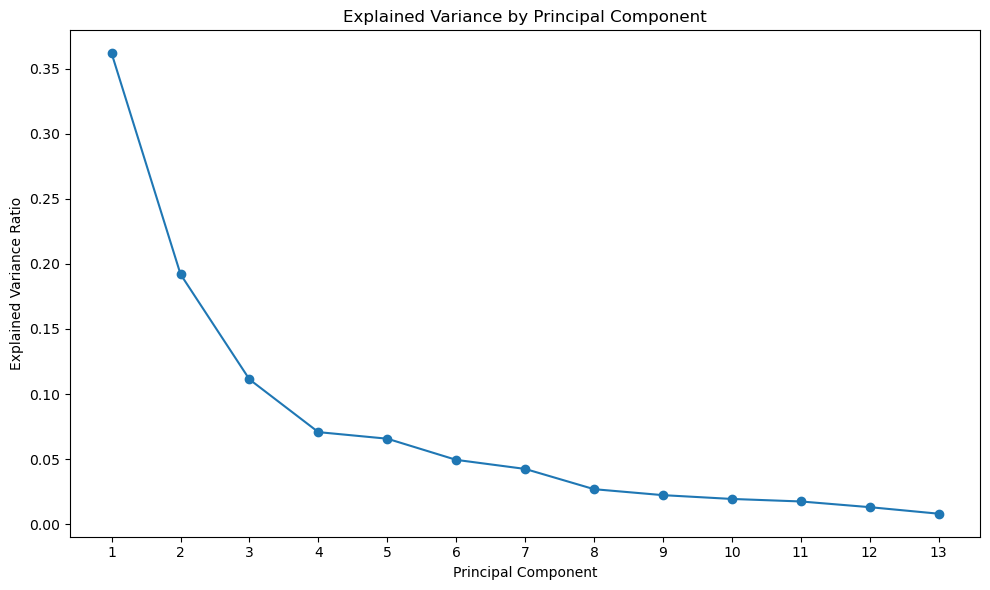

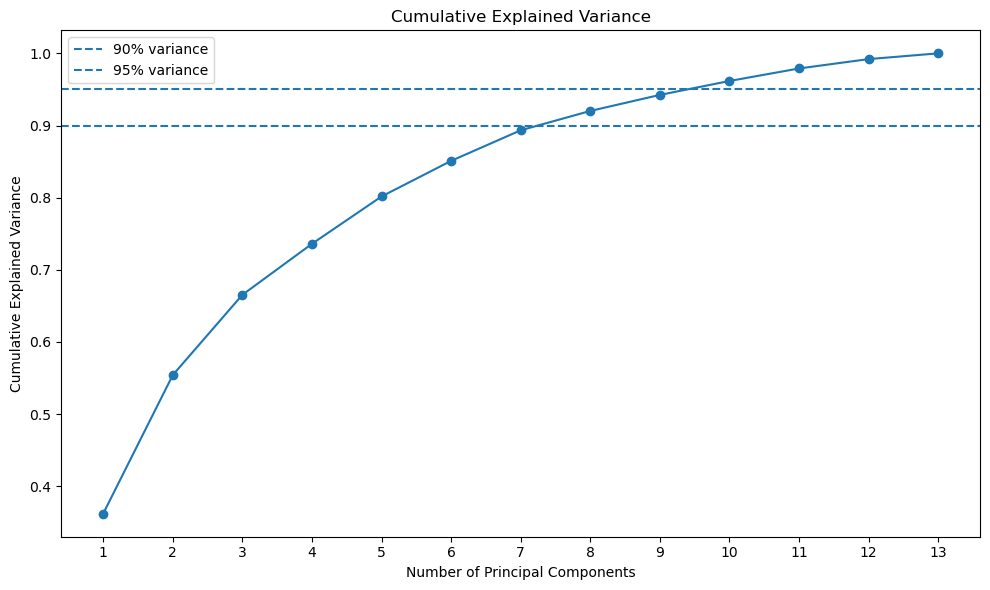

In [7]:
plt.figure()
plt.plot(
    variance_table["Component"],
    variance_table["Explained_Variance_Ratio"],
    marker="o"
)
plt.title("Explained Variance by Principal Component")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.xticks(variance_table["Component"])
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(
    variance_table["Component"],
    variance_table["Cumulative_Variance"],
    marker="o"
)
plt.axhline(0.90, linestyle="--", label="90% variance")
plt.axhline(0.95, linestyle="--", label="95% variance")
plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.xticks(variance_table["Component"])
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
# Choose the smallest number of components explaining at least 90% of variance.
n_90 = int(np.argmax(cumulative_variance >= 0.90) + 1)

# Also report the number needed for 95% variance.
n_95 = int(np.argmax(cumulative_variance >= 0.95) + 1)

print(f"Components required for >=90% variance: {n_90}")
print(f"Components required for >=95% variance: {n_95}")

Components required for >=90% variance: 8
Components required for >=95% variance: 10


In [9]:
# Two components are especially useful for visual inspection.
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca_2,
    columns=["PC1", "PC2"]
)
pca_df["Customer_Segment"] = y.values

print("Reduced dataset shape:", pca_df.shape)
display(pca_df.head())

print("\nVariance captured by PC1 and PC2:")
print(f"PC1: {pca_2.explained_variance_ratio_[0]:.4f}")
print(f"PC2: {pca_2.explained_variance_ratio_[1]:.4f}")
print(f"Total: {pca_2.explained_variance_ratio_.sum():.4f}")

Reduced dataset shape: (178, 3)


,PC1,PC2,Customer_Segment
0,3.316751,1.443463,1
1,2.209465,-0.333393,1
2,2.516740,1.031151,1
3,3.757066,2.756372,1
4,1.008908,0.869831,1



Variance captured by PC1 and PC2:
PC1: 0.3620
PC2: 0.1921
Total: 0.5541


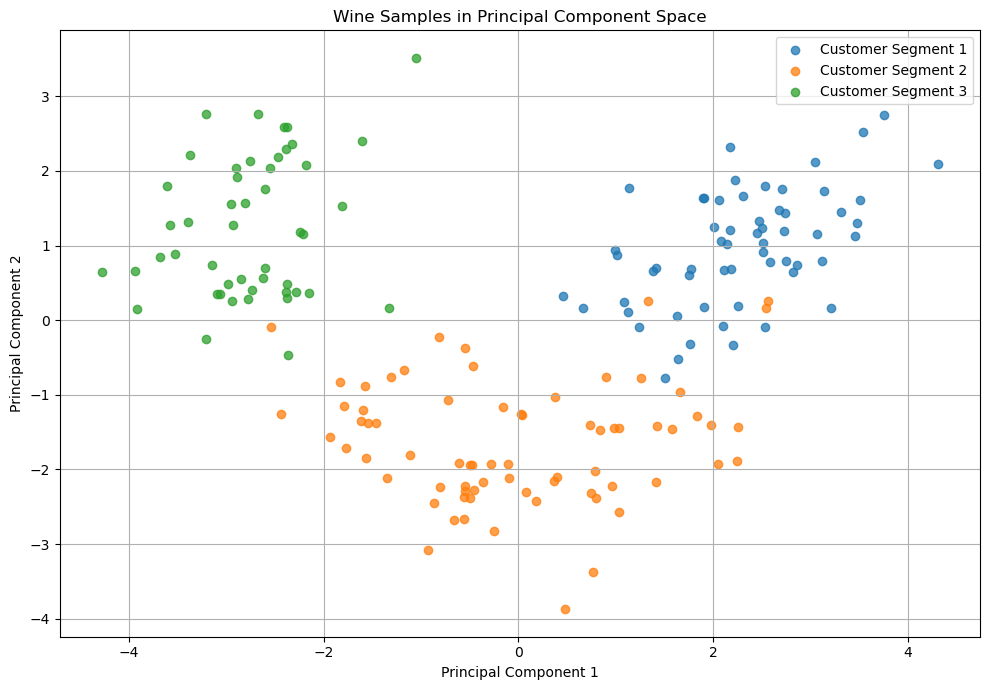

In [10]:
plt.figure(figsize=(10, 7))

for segment in sorted(pca_df["Customer_Segment"].unique()):
    subset = pca_df[pca_df["Customer_Segment"] == segment]
    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Customer Segment {segment}",
        alpha=0.75
    )

plt.title("Wine Samples in Principal Component Space")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()